# Task-specific cfDNA baselines

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

LEAF-1 against the task-specific cfDNA methods (end-motif 4-mer, EMIT,
GALYFRE), as a main-figure panel. The representation-paradigm baselines (5-mer,
10kb bin + DELFI, DELFI) are already in Fig. 4b/c and are not repeated here; the
reviewer-response version with all seven bars is
`output/cfdna/taskspecific/cfdna_taskspecific_benchmark.png` and is not kept in
this directory.

Bars are the mean over the 14 cfDNA detection tasks -- the seven
one-cancer-vs-other-cancers and seven one-cancer-vs-healthy comparisons.
Pan-cancer is reported separately and is not in the mean, matching Fig. 4b/c.

Panel:
- `cfdna_taskspecific_main`: mean AUC per method with BCa 95% CI.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


In [2]:
# ── Constants ─────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.transforms as mtrans
from matplotlib.patches import Patch
from scipy import stats as sp_stats

OKABE_BLUE = OKABE_ITO["blue"]
OKABE_VERM = OKABE_ITO["vermillion"]
# The grey sits below 3:1 against the surface, which is why every bar carries a
# visible value label -- the documented relief for a low-contrast fill.
BASELINE_GREY = "#BCBCBC"

REFERENCE = "internal[cut,mod,fragment1]"
TASKS = [
    f"{c}_cancer_vs_{a}"
    for a in ("cancer", "healthy")
    for c in ("Bile_duct", "Breast", "Colorectal", "Gastric", "Lung",
              "Ovarian", "Pancreatic")
]
# (table key, display label, group)
ROWS = [
    (REFERENCE,        "LEAF-1",           "leaf"),
    ("end-motif-4mer", "End-motif 4-mer",  "new"),
    ("emit",           "EMIT",             "new"),
    ("galyfre",        "GALYFRE",          "new"),
    ("kmer-5",         "5-mer",            "old"),
    ("bin-10K_delfi",  "10kb Bin + DELFI", "old"),
    ("delfi",          "DELFI",            "old"),
]
COLOR = {"leaf": OKABE_BLUE, "new": OKABE_VERM, "old": BASELINE_GREY}

# This panel is drawn one size up from the shared paper style so it matches the
# manuscript's existing representation-benchmark figures.
PANEL_RC = {
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 6.5,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 3, "ytick.major.size": 3, "lines.linewidth": 1.0,
}


def bca_ci(vals, n_resamples=9999, seed=42):
    """Mean and BCa 95% CI -- the same call the manuscript's panels use."""
    a = np.asarray(vals, dtype=float)
    r = sp_stats.bootstrap((a,), np.mean, n_resamples=n_resamples,
                           confidence_level=0.95, method="BCa",
                           random_state=np.random.default_rng(seed))
    return (float(np.mean(a)), float(r.confidence_interval.low),
            float(r.confidence_interval.high))


d = pd.read_csv(DATA / "cfdna_taskspecific_auc.csv", index_col=0)
rows = [r for r in ROWS if r[0] in d.index]
per_task = {k: d.loc[k, TASKS].astype(float).values for k, _, _ in rows}
rows = sorted(rows, key=lambda r: -per_task[r[0]].mean())
print(f"{len(rows)} representations x {len(TASKS)} tasks")

7 representations x 14 tasks


## Figure

Drawn with
Fig. 4c's code (`cfdna_kmer_benchmark` in leaf-1-figures
`cfdna_representation_benchmark.ipynb`): the same rcParams, bar width, BCa error
bars, jitter, value labels, rotated tick labels and outward spines, LEAF-1 in
blue and every comparator in the same grey, no legend. Figure width is scaled
from 5.5 in for five bars to four, so each bar is as wide as in Fig. 4c.

Two deliberate differences: the y axis starts at 0.4 because one EMIT task sits
at 0.458, below Fig. 4c's 0.48 floor; and each value label sits on a faint white
halo because the per-task circles reach above the CI
caps.

Panel:
- `cfdna_taskspecific_main`

saved: cfdna/output/cfdna_taskspecific_main.pdf
saved: cfdna/output/cfdna_taskspecific_main.png
saved: cfdna/output/cfdna_taskspecific_main.svg
saved: cfdna/output/cfdna_taskspecific_main.tsv


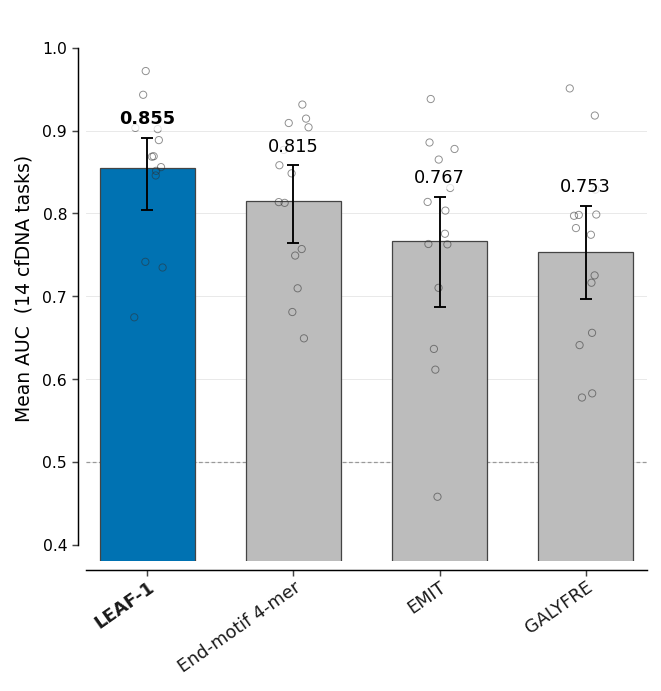

                      model           label  mean_auc  ci_low  ci_high  n_tasks
internal[cut,mod,fragment1]          LEAF-1    0.8550  0.8043   0.8911       14
             end-motif-4mer End-motif 4-mer    0.8154  0.7646   0.8582       14
                       emit            EMIT    0.7666  0.6877   0.8198       14
                    galyfre         GALYFRE    0.7535  0.6971   0.8093       14
lowest per-task AUC shown: 0.4581


In [3]:
# ── Main figure: LEAF-1 vs task-specific methods, Fig. 4c style ──────────────
FIG4C_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica", "Liberation Sans"],
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 6.5,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 3, "ytick.major.size": 3, "lines.linewidth": 1.0,
    "axes.spines.top": False, "axes.spines.right": False,
}
main_rows = [r for r in rows if r[2] in ("leaf", "new")]     # already sorted by mean

with plt.rc_context(FIG4C_RC):
    fig, ax = plt.subplots(figsize=(5.5 * len(main_rows) / 5, 4.5))
    x = np.arange(len(main_rows))
    means, err_lo, err_hi = [], [], []
    for key, _, _ in main_rows:
        mu, lo, hi = bca_ci(per_task[key])
        means.append(mu); err_lo.append(mu - lo); err_hi.append(hi - mu)

    ax.bar(x, means, width=0.65,
           color=[OKABE_BLUE if k == REFERENCE else BASELINE_GREY for k, _, _ in main_rows],
           edgecolor="#444444", linewidth=0.6, zorder=2,
           yerr=[err_lo, err_hi], capsize=3,
           error_kw={"linewidth": 0.9, "capthick": 0.9, "color": "#1A1A1A", "zorder": 4})
    yticks = [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    for yt in yticks[1:-1]:
        ax.axhline(yt, color="#E5E5E5", lw=0.4, zorder=0)
    ax.axhline(0.5, color="#999999", linestyle=(0, (3, 2)), linewidth=0.6, zorder=1)

    rng = np.random.default_rng(42)
    for i, (key, _, _) in enumerate(main_rows):
        vals = per_task[key]
        jit = rng.uniform(-0.11, 0.11, size=len(vals))
        ax.scatter(np.full(len(vals), i) + jit, vals, facecolors="none",
                   edgecolors="#303030", linewidth=0.45, alpha=0.55, s=12, zorder=3)
    for i, (mu, eh) in enumerate(zip(means, err_hi)):
        ax.text(i, mu + eh + 0.012, f"{mu:.3f}", ha="center", va="bottom",
                fontsize=8.5, zorder=5,
                fontweight="bold" if main_rows[i][0] == REFERENCE else "normal",
                bbox=dict(boxstyle="round,pad=0.12", facecolor="white",
                          edgecolor="none", alpha=0.75))

    ax.set_ylabel("Mean AUC  (14 cfDNA tasks)", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels([""] * len(x))
    ax.tick_params(axis="x", which="major", length=3, pad=2, color="#444444")
    trans = mtrans.blended_transform_factory(ax.transData, ax.transAxes)
    offset = mtrans.ScaledTranslation(0, -8 / 72.0, fig.dpi_scale_trans)
    for xi, (key, label, _) in zip(x, main_rows):
        ax.text(xi, 0, label, transform=trans + offset, rotation=35, ha="right",
                va="top", rotation_mode="anchor", fontsize=8.5,
                fontweight="bold" if key == REFERENCE else "normal",
                color="#1A1A1A", clip_on=False)
    ax.set_yticks(yticks); ax.set_ylim(0.38, 1.04)
    XPAD = 0.42
    ax.set_xlim(x[0] - XPAD, x[-1] + XPAD)
    ax.spines["left"].set_position(("outward", 4))
    ax.spines["bottom"].set_position(("outward", 4))
    ax.spines["bottom"].set_bounds(x[0] - XPAD, x[-1] + XPAD)
    ax.spines["left"].set_bounds(yticks[0], yticks[-1])
    ax.tick_params(axis="y", which="both", length=3, pad=2, color="#444444")
    plt.subplots_adjust(left=0.13, right=0.98, bottom=0.16, top=0.97)

    tidy_main = pd.DataFrame({
        "model": [k for k, _, _ in main_rows],
        "label": [lab for _, lab, _ in main_rows],
        "mean_auc": means,
        "ci_low": [m - e for m, e in zip(means, err_lo)],
        "ci_high": [m + e for m, e in zip(means, err_hi)],
        "n_tasks": [len(TASKS)] * len(main_rows),
    })
    savefig(fig, OUT, "cfdna_taskspecific_main", data=tidy_main)
    plt.show()

print(tidy_main.round(4).to_string(index=False))
print("lowest per-task AUC shown:", round(min(per_task[k].min() for k, _, _ in main_rows), 4))